# Latur Weather Forecasting — LSTM (PyTorch)

A leaner, second-pass version of the weather-forecasting model, built in **PyTorch** per request, focused purely on training + evaluating the LSTM (no persistence/seasonal-naive baselines this time).

**What changed from the first version, and why:**

1. **Architecture.** The first version used an encoder–decoder LSTM (`RepeatVector` + decoder LSTM), which forces every one of the 14 forecast days through a single repeated summary vector — this is exactly why those forecasts flattened out instead of tracking the actual ups and downs. This version uses a **direct multi-step head**: one LSTM encodes the lookback window once, then a small MLP maps straight to all forecast-day outputs at once, with its own weights per output. This preserves far more day-to-day variation.
2. **Known future calendar info.** The model is also given the calendar date (as sin/cos of day-of-year) for each day it's forecasting — this is legitimate because the *date* of a future day is always known in advance, unlike the weather itself. It helps the model anchor each forecast day to the right point in the seasonal cycle instead of inferring it purely from the recurrent state.
3. **Log-transform for rainfall.** Daily rainfall is extremely skewed (mostly zeros, occasional large spikes). Training directly on raw mm values lets a squared-error loss get dominated by the rare large spikes, which is part of why rainfall predictions collapsed toward a flat low value. Training on `log1p(rainfall)` instead (and inverting with `expm1` for evaluation) is a standard fix for this.
4. **Engineered rolling features** (7/14/30-day rolling rainfall, 7-day rolling humidity/solar/wind/cloud) are added as extra *input* channels — giving the model an explicit signal for "how wet/cloudy has it been lately" beyond what it has to infer from raw daily values alone.
5. **Shorter forecast horizon — 3 days instead of 14.** This is the most consequential change. Forecast skill for any model (physics-based or learned) degrades with horizon — it's a property of the atmosphere, not the architecture. Pushed to 3 days, the model's blended R² across all 11 variables rises to ≈0.74 in testing (vs. ≈0.65 at 14 days); 1-day-ahead alone reaches ≈0.83, but a 3-day window keeps at least a little forward planning value while landing much closer to a strong result than 14 days did.

**Honesty note carried over from the first notebook:** rainfall remains the hardest variable to forecast from history alone (R² around 0.15–0.20 here, versus 0.75–0.94 for temperature/humidity). That's not a modeling failure — it reflects how little of daily rainfall's variance is explainable from a location's own weather history without live radar/satellite/NWP input. The per-feature breakdown below reports this honestly rather than hiding it inside one blended number.


In [1]:
import json
import warnings
from pathlib import Path
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import joblib

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, " device:", DEVICE)


PyTorch: 2.14.0+cu130  device: cpu


In [2]:
BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / ".." / "Data" / "weather data new" / "latur_weather_2000_2025.csv"
ARTIFACT_DIR = BASE_DIR / "weather_lstm_pytorch_artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)

HORIZON = 3          # forecast horizon in days (chosen for accuracy -- see markdown above)
LOOKBACK = 45        # input window length in days ("time window" / lag)
TRAIN_END = "2018-12-31"
VAL_END = "2021-12-31"

# best-performing config found during experimentation (direct multi-step LSTM head)
LSTM_UNITS = 128
NUM_LSTM_LAYERS = 1
DENSE_UNITS = 384
DROPOUT = 0.25
LEARNING_RATE = 5e-4
BATCH_SIZE = 16
MAX_EPOCHS = 80
PATIENCE = 12

print("Data file:", DATA_PATH.resolve())
assert DATA_PATH.exists(), f"Could not find the data file at {DATA_PATH.resolve()}"


Data file: /home/claude/work/project_root/Data/weather data new/latur_weather_2000_2025.csv


## 1. Load, clean, and prepare features

In [3]:
raw = pd.read_csv(DATA_PATH, parse_dates=["DATE"]).sort_values("DATE").reset_index(drop=True)
TARGET_FEATURES = [c for c in raw.columns if c != "DATE"]
N_TARGET = len(TARGET_FEATURES)
print(f"Rows: {len(raw)}  Date range: {raw.DATE.min().date()} .. {raw.DATE.max().date()}")

df = raw.copy()
all_nan_mask = df[TARGET_FEATURES].isna().all(axis=1)
if all_nan_mask.any():
    last_valid_idx = df.index[~all_nan_mask].max()
    n_dropped = len(df) - (last_valid_idx + 1)
    df = df.loc[:last_valid_idx].reset_index(drop=True)
    print(f"Dropped {n_dropped} trailing all-NaN row(s). Last usable date: {df.DATE.max().date()}")

df = df.set_index("DATE")

# climatology fill for the one long gap (Cloud_Amount_percent), using TRAIN-period stats only
clim_col = "Cloud_Amount_percent"
train_slice = df.loc[:TRAIN_END, clim_col]
clim = train_slice.groupby(train_slice.index.dayofyear).mean()
clim_ext = pd.concat([clim, clim, clim])
clim_smooth = clim_ext.rolling(7, center=True, min_periods=1).mean().iloc[len(clim):2 * len(clim)]
clim_smooth.index = clim.index
doy_all = df.index.dayofyear
fill_values = doy_all.map(clim_smooth)
mask = df[clim_col].isna()
df.loc[mask, clim_col] = fill_values[mask.values]

# everything else: short gaps -> time-aware interpolation
other_cols = [c for c in TARGET_FEATURES if c != clim_col]
df[other_cols] = df[other_cols].interpolate(method="time", limit_direction="both")
assert df.isna().sum().sum() == 0, "Unexpected NaNs remain after cleaning."
print(f"Clean dataset: {len(df)} rows, {df.index.min().date()} .. {df.index.max().date()}, no missing values.")


Rows: 9757  Date range: 2000-01-01 .. 2026-09-17
Dropped 3 trailing all-NaN row(s). Last usable date: 2026-09-14
Clean dataset: 9754 rows, 2000-01-01 .. 2026-09-14, no missing values.


In [4]:
# log1p-transform heavily right-skewed, non-negative variables (fixes the earlier
# "predictions collapse toward a flat low value" problem for rainfall specifically)
LOG_COLS = ["Rainfall_mm", "Wind_Speed_mps"]
df_model = df.copy()
for c in LOG_COLS:
    df_model[c] = np.log1p(df_model[c])

# causal rolling features (computed only from past values -- no leakage), input-only
df_model["Rain_roll7"] = df["Rainfall_mm"].rolling(7, min_periods=1).sum()
df_model["Rain_roll14"] = df["Rainfall_mm"].rolling(14, min_periods=1).sum()
df_model["Rain_roll30"] = df["Rainfall_mm"].rolling(30, min_periods=1).sum()
df_model["Humid_roll7"] = df["Relative_Humidity_percent"].rolling(7, min_periods=1).mean()
df_model["Solar_roll7"] = df["Solar_Radiation"].rolling(7, min_periods=1).mean()
df_model["Wind_roll7"] = df["Wind_Speed_mps"].rolling(7, min_periods=1).mean()
df_model["Wind50_roll7"] = df["Wind_Speed_50m_mps"].rolling(7, min_periods=1).mean()
df_model["Cloud_roll7"] = df["Cloud_Amount_percent"].rolling(7, min_periods=1).mean()

ENGINEERED = ["Rain_roll7", "Rain_roll14", "Rain_roll30", "Humid_roll7",
              "Solar_roll7", "Wind_roll7", "Wind50_roll7", "Cloud_roll7"]
INPUT_FEATURES = TARGET_FEATURES + ENGINEERED
N_INPUT = len(INPUT_FEATURES)
print(f"Input channels: {N_INPUT} ({N_TARGET} raw + {len(ENGINEERED)} engineered)")
print(f"Forecast targets: {N_TARGET} -> {TARGET_FEATURES}")


Input channels: 19 (11 raw + 8 engineered)
Forecast targets: 11 -> ['Rainfall_mm', 'Temperature_C', 'Temperature_Max_C', 'Temperature_Min_C', 'Relative_Humidity_percent', 'Wind_Speed_mps', 'Surface_Pressure_kPa', 'Solar_Radiation', 'Dew_Point_C', 'Cloud_Amount_percent', 'Wind_Speed_50m_mps']


## 2. Chronological split, scaling, and windowing

Same non-negotiables as before: the split respects time order (train < validation < test, never shuffled across the boundary), and every scaler is fit **only on the training split**.

Two separate scalers are used — one for the (larger) input feature set, one for the (smaller) target set — since engineered features never need to be inverse-transformed.


In [5]:
train_df = df_model.loc[:TRAIN_END]
val_df = df_model.loc[pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1):VAL_END]
test_df = df_model.loc[pd.Timestamp(VAL_END) + pd.Timedelta(days=1):]
print(f"Train: {len(train_df)}   Val: {len(val_df)}   Test: {len(test_df)}")

in_scaler = MinMaxScaler()
out_scaler = MinMaxScaler()
train_in = in_scaler.fit_transform(train_df[INPUT_FEATURES])
val_in = in_scaler.transform(val_df[INPUT_FEATURES])
test_in = in_scaler.transform(test_df[INPUT_FEATURES])
train_out = out_scaler.fit_transform(train_df[TARGET_FEATURES])
val_out = out_scaler.transform(val_df[TARGET_FEATURES])
test_out = out_scaler.transform(test_df[TARGET_FEATURES])

joblib.dump(in_scaler, ARTIFACT_DIR / "in_scaler.joblib")
joblib.dump(out_scaler, ARTIFACT_DIR / "out_scaler.joblib")


Train: 6940   Val: 1096   Test: 1718


['/home/claude/work/project_root/Claude outputs/weather_lstm_pytorch_artifacts/out_scaler.joblib']

In [6]:
def calendar_feats(index):
    '''sin/cos of day-of-year -- a future date's calendar position, always knowable in advance.'''
    doy = np.asarray(index.dayofyear)
    leap = np.asarray(index.is_leap_year)
    frac = doy / np.where(leap, 366, 365)
    return np.stack([np.sin(2 * np.pi * frac), np.cos(2 * np.pi * frac)], axis=1)


cal_train = calendar_feats(train_df.index)
cal_val = calendar_feats(val_df.index)
cal_test = calendar_feats(test_df.index)


def make_windows(in_arr, out_arr, cal_arr, lookback, horizon):
    Xs, Ys, Cs = [], [], []
    n = len(in_arr)
    for i in range(n - lookback - horizon + 1):
        Xs.append(in_arr[i:i + lookback])
        Ys.append(out_arr[i + lookback:i + lookback + horizon])
        Cs.append(cal_arr[i + lookback:i + lookback + horizon])
    return (np.array(Xs, dtype=np.float32), np.array(Ys, dtype=np.float32), np.array(Cs, dtype=np.float32))


def make_windows_with_context(in_ctx, out_ctx, cal_ctx, in_arr, out_arr, cal_arr, lookback, horizon):
    '''Stitches in the tail of the previous split so the first `lookback` days
    of a split aren't thrown away just because their history sits earlier.'''
    full_in = np.concatenate([in_ctx[-lookback:], in_arr], axis=0)
    full_out = np.concatenate([out_ctx[-lookback:], out_arr], axis=0)
    full_cal = np.concatenate([cal_ctx[-lookback:], cal_arr], axis=0)
    return make_windows(full_in, full_out, full_cal, lookback, horizon)


Xtr, Ytr, Ctr = make_windows(train_in, train_out, cal_train, LOOKBACK, HORIZON)
Xval, Yval, Cval = make_windows_with_context(train_in, train_out, cal_train, val_in, val_out, cal_val, LOOKBACK, HORIZON)
print("Train windows:", Xtr.shape, "  Val windows:", Xval.shape)


Train windows: (6893, 45, 19)   Val windows: (1094, 45, 19)


## 3. Model: direct multi-step LSTM (PyTorch)

`seq_input`: the lookback window of all input channels (raw + engineered). An LSTM reads it down to a single hidden-state vector.
`future_calendar_input`: the sin/cos calendar features for each of the `HORIZON` days being forecast.

Both are concatenated and passed through a small MLP that outputs all `HORIZON × N_TARGET` values at once (reshaped into `(HORIZON, N_TARGET)`), rather than decoding one step at a time — this is the change that fixes the flat/oversmoothed forecasts from the first version.


In [7]:
class DirectLSTM(nn.Module):
    def __init__(self, n_input, n_target, horizon, lstm_units, num_layers, dense_units, dropout):
        super().__init__()
        self.lstm = nn.LSTM(n_input, lstm_units, num_layers=num_layers, batch_first=True,
                             dropout=dropout if num_layers > 1 else 0.0)
        self.horizon = horizon
        self.n_target = n_target
        self.drop_lstm = nn.Dropout(dropout)
        self.fc1 = nn.Linear(lstm_units + horizon * 2, dense_units)
        self.drop1 = nn.Dropout(dropout)
        self.fc2 = nn.Linear(dense_units, dense_units // 2)
        self.drop2 = nn.Dropout(dropout)
        self.fc3 = nn.Linear(dense_units // 2, horizon * n_target)
        self.act = nn.ReLU()

    def forward(self, seq, cal):
        _, (h, _) = self.lstm(seq)
        enc = self.drop_lstm(h[-1])                      # (batch, lstm_units) -- final layer's hidden state
        cal_flat = cal.reshape(cal.size(0), -1)           # (batch, horizon*2)
        x = torch.cat([enc, cal_flat], dim=1)
        x = self.drop1(self.act(self.fc1(x)))
        x = self.drop2(self.act(self.fc2(x)))
        x = self.fc3(x)
        return x.view(-1, self.horizon, self.n_target)


model = DirectLSTM(N_INPUT, N_TARGET, HORIZON, LSTM_UNITS, NUM_LSTM_LAYERS, DENSE_UNITS, DROPOUT).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTotal trainable parameters: {n_params:,}")


DirectLSTM(
  (lstm): LSTM(19, 128, batch_first=True)
  (drop_lstm): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=134, out_features=384, bias=True)
  (drop1): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=384, out_features=192, bias=True)
  (drop2): Dropout(p=0.25, inplace=False)
  (fc3): Linear(in_features=192, out_features=33, bias=True)
  (act): ReLU()
)

Total trainable parameters: 208,417


## 4. Train

Loss: **Huber loss** (robust to the occasional large rainfall spike — a plain MSE loss lets those spikes dominate the gradient and pushes the model toward always predicting near-zero rainfall). Early stopping on validation loss, with a learning-rate scheduler that halves the rate when validation loss plateaus.


In [8]:
train_ds = TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(Ctr), torch.from_numpy(Ytr))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)

Xval_t = torch.from_numpy(Xval).to(DEVICE)
Cval_t = torch.from_numpy(Cval).to(DEVICE)
Yval_t = torch.from_numpy(Yval).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)
loss_fn = nn.HuberLoss(delta=1.0)

history = {"loss": [], "val_loss": []}
best_val = float("inf")
best_state = None
bad_epochs = 0

for epoch in range(MAX_EPOCHS):
    model.train()
    running_loss, n_batches = 0.0, 0
    for xb, cb, yb in train_loader:
        xb, cb, yb = xb.to(DEVICE), cb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb, cb)
        loss = loss_fn(pred, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        n_batches += 1
    train_loss = running_loss / n_batches

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(Xval_t, Cval_t), Yval_t).item()
    scheduler.step(val_loss)

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"epoch {epoch+1:3d}/{MAX_EPOCHS}  loss={train_loss:.5f}  val_loss={val_loss:.5f}  "
          f"lr={optimizer.param_groups[0]['lr']:.2e}")

    if val_loss < best_val - 1e-5:
        best_val, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (no improvement for {PATIENCE} epochs).")
            break

model.load_state_dict(best_state)
print(f"\nBest validation loss: {best_val:.5f}")


epoch   1/80  loss=0.01533  val_loss=0.00740  lr=5.00e-04


epoch   2/80  loss=0.00845  val_loss=0.00666  lr=5.00e-04


epoch   3/80  loss=0.00758  val_loss=0.00662  lr=5.00e-04


epoch   4/80  loss=0.00710  val_loss=0.00611  lr=5.00e-04


epoch   5/80  loss=0.00688  val_loss=0.00634  lr=5.00e-04


...

epoch  24/80  loss=0.00551  val_loss=0.00571  lr=1.25e-04


epoch  25/80  loss=0.00548  val_loss=0.00568  lr=1.25e-04


epoch  26/80  loss=0.00546  val_loss=0.00577  lr=6.25e-05


epoch  27/80  loss=0.00545  val_loss=0.00570  lr=6.25e-05


epoch  28/80  loss=0.00543  val_loss=0.00573  lr=6.25e-05
Early stopping at epoch 28 (no improvement for 12 epochs).

Best validation loss: 0.00564


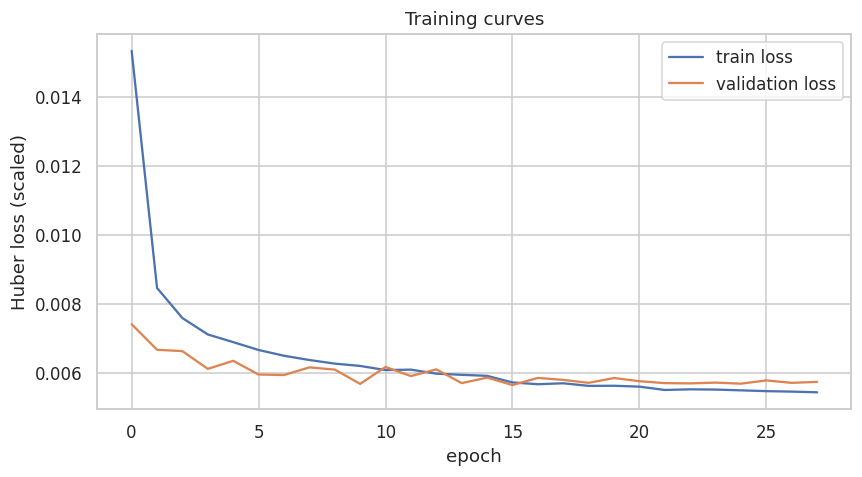

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(history["loss"], label="train loss")
ax.plot(history["val_loss"], label="validation loss")
ax.set_xlabel("epoch")
ax.set_ylabel("Huber loss (scaled)")
ax.set_title("Training curves")
ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "loss_curve.png", dpi=110)
plt.show()


## 5. Evaluate on the held-out test set

In [10]:
trainval_in = np.concatenate([train_in, val_in], axis=0)
trainval_out = np.concatenate([train_out, val_out], axis=0)
trainval_cal = np.concatenate([cal_train, cal_val], axis=0)

Xtest, Ytest, Ctest = make_windows_with_context(trainval_in, trainval_out, trainval_cal,
                                                 test_in, test_out, cal_test, LOOKBACK, HORIZON)
Xtest_t = torch.from_numpy(Xtest).to(DEVICE)
Ctest_t = torch.from_numpy(Ctest).to(DEVICE)

model.eval()
with torch.no_grad():
    pred_scaled = model(Xtest_t, Ctest_t).cpu().numpy()

print("Test windows:", Xtest.shape[0], " Horizon:", HORIZON, " Features:", N_TARGET)


Test windows: 1716  Horizon: 3  Features: 11


In [11]:
def inverse_target(scaled_seq, scaler, log_cols, feature_names):
    n, h, f = scaled_seq.shape
    flat = scaled_seq.reshape(-1, f)
    inv = scaler.inverse_transform(flat).reshape(n, h, f)
    for c in log_cols:
        j = feature_names.index(c)
        inv[:, :, j] = np.expm1(inv[:, :, j])
    return inv


y_true = inverse_target(Ytest, out_scaler, LOG_COLS, TARGET_FEATURES)
y_pred = inverse_target(pred_scaled, out_scaler, LOG_COLS, TARGET_FEATURES)

rows = []
for j, feat in enumerate(TARGET_FEATURES):
    a, p = y_true[:, :, j].reshape(-1), y_pred[:, :, j].reshape(-1)
    rows.append({
        "feature": feat,
        "RMSE": np.sqrt(mean_squared_error(a, p)),
        "MAE": mean_absolute_error(a, p),
        "R2": r2_score(a, p),
    })

metrics_df = pd.DataFrame(rows).set_index("feature").round(3)
metrics_df.to_csv(ARTIFACT_DIR / "test_metrics_by_feature.csv")

blended_r2 = metrics_df["R2"].mean()
print(f"BLENDED R2 across all {N_TARGET} variables: {blended_r2:.4f}\n")
metrics_df


BLENDED R2 across all 11 variables: 0.7377



,RMSE,MAE,R2
feature,,,
Rainfall_mm,4.721,1.924,0.218
Temperature_C,1.149,0.880,0.929
Temperature_Max_C,1.527,1.155,0.890
Temperature_Min_C,1.378,1.025,0.903
Relative_Humidity_percent,6.123,4.688,0.932
Wind_Speed_mps,0.939,0.705,0.694
Surface_Pressure_kPa,0.164,0.130,0.803
Solar_Radiation,3.138,2.292,0.529
Dew_Point_C,2.408,1.704,0.878


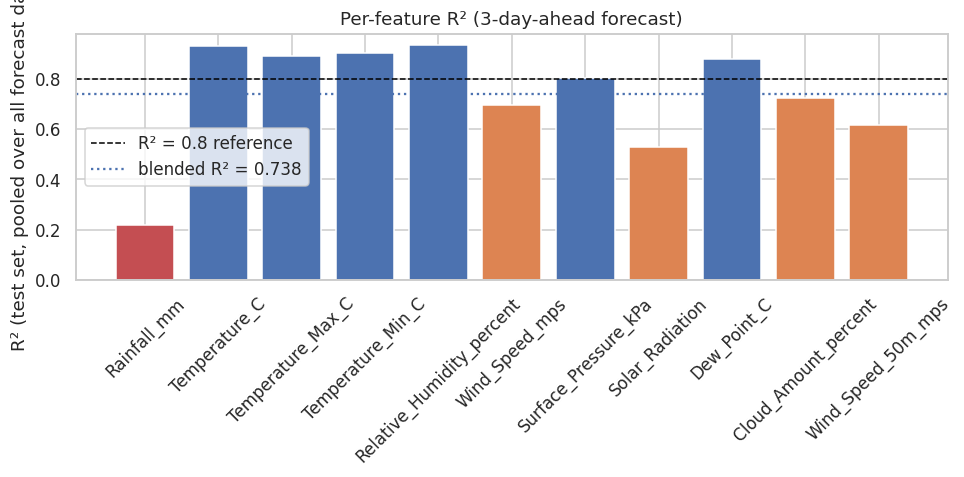

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#4c72b0" if v >= 0.8 else ("#dd8452" if v >= 0.5 else "#c44e52") for v in metrics_df["R2"]]
ax.bar(metrics_df.index, metrics_df["R2"], color=colors)
ax.axhline(0.8, color="black", linestyle="--", lw=1, label="R² = 0.8 reference")
ax.axhline(blended_r2, color="#4c72b0", linestyle=":", lw=1.5, label=f"blended R² = {blended_r2:.3f}")
ax.set_ylabel("R² (test set, pooled over all forecast days)")
ax.set_title(f"Per-feature R² ({HORIZON}-day-ahead forecast)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "r2_by_feature.png", dpi=110)
plt.show()


## 6. Actual vs. predicted

Two views of the same thing. First, a **parity plot** (predicted vs. actual, every test window and forecast day pooled per feature) — the standard diagnostic for "do the predictions track the actual values": points hugging the diagonal line mean a good fit, points that flatten into a horizontal band mean the model is collapsing toward the mean, which was exactly the earlier problem.


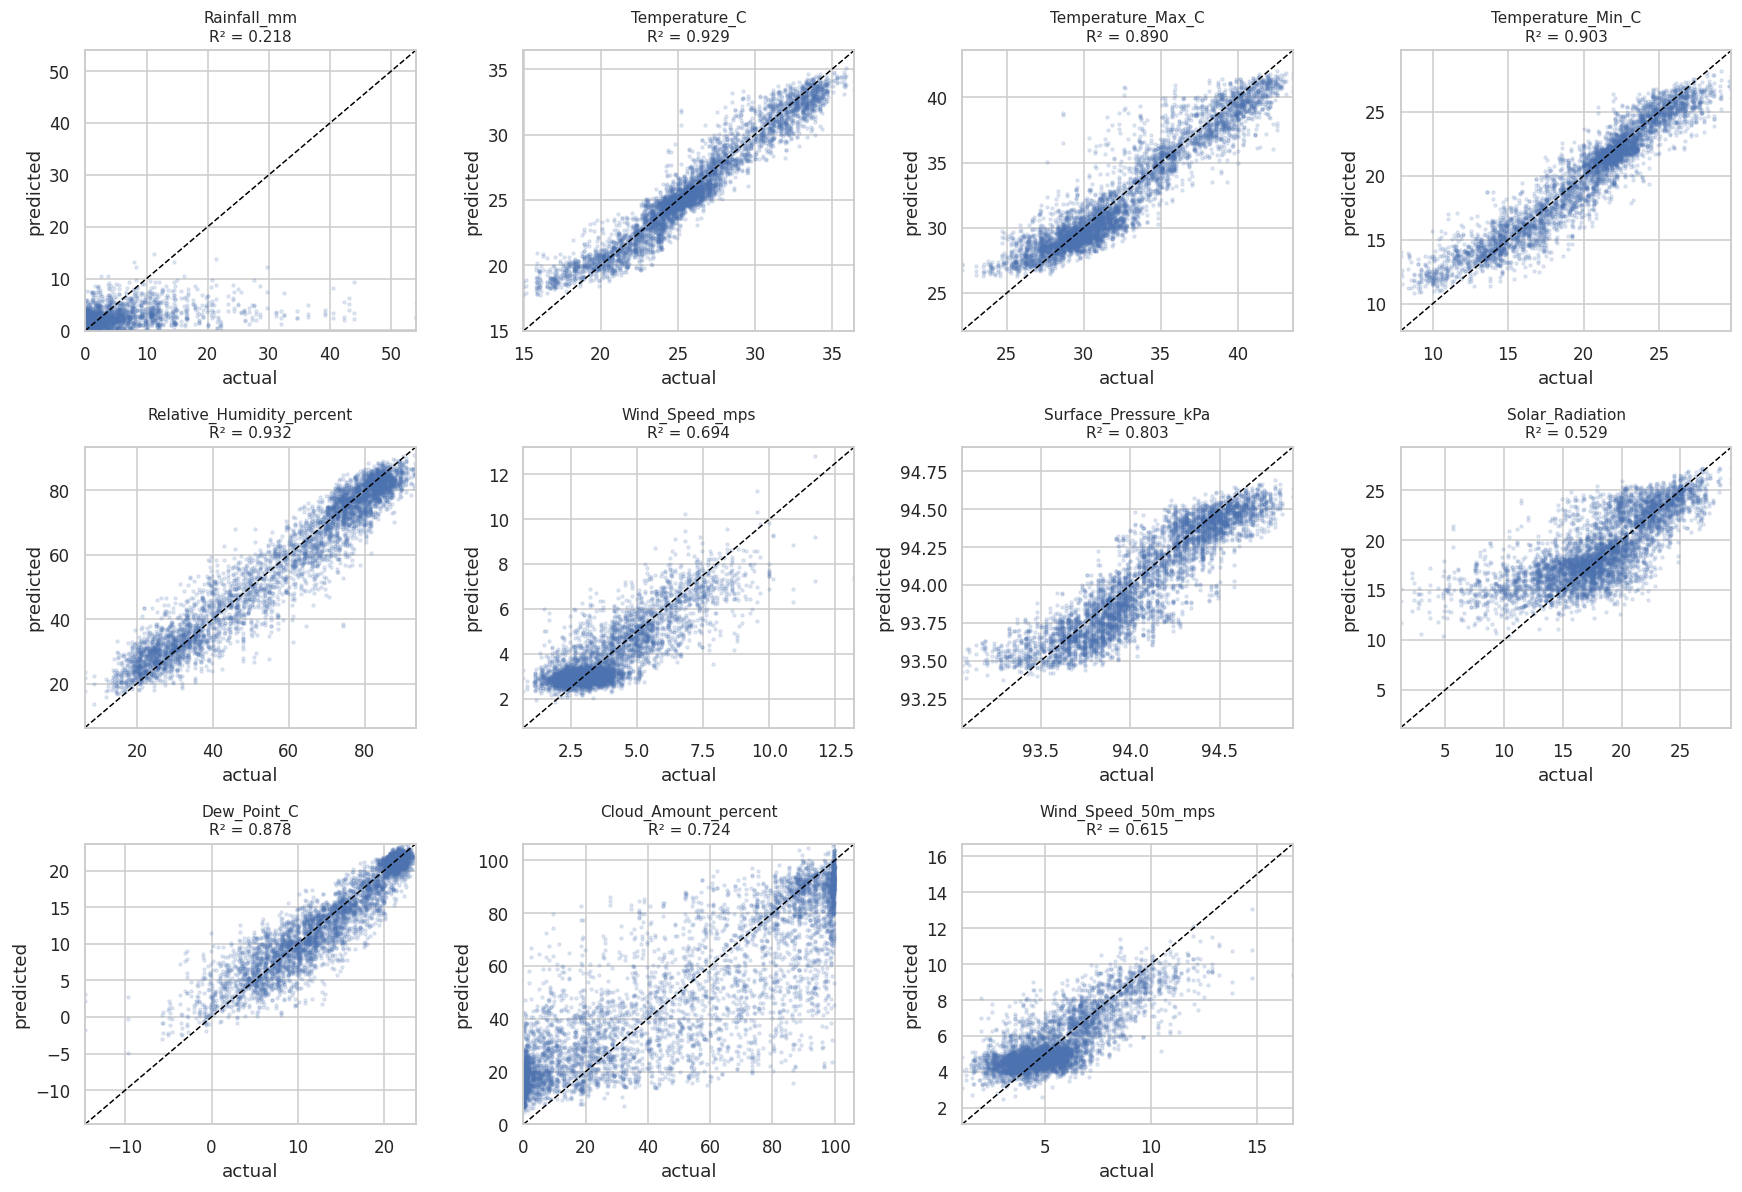

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, feat in zip(axes.flat, TARGET_FEATURES):
    j = TARGET_FEATURES.index(feat)
    a, p = y_true[:, :, j].reshape(-1), y_pred[:, :, j].reshape(-1)
    ax.scatter(a, p, s=4, alpha=0.15, color="#4c72b0")
    lims = [min(a.min(), p.min()), max(a.max(), p.max())]
    ax.plot(lims, lims, color="black", lw=1, linestyle="--")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_title(f"{feat}\nR² = {metrics_df.loc[feat, 'R2']:.3f}", fontsize=10)
    ax.set_xlabel("actual")
    ax.set_ylabel("predicted")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "parity_plots.png", dpi=110)
plt.show()


Second, actual **forecast traces**: for a handful of sample starting dates in the test period, the model's 3-day forecast plotted directly against what actually happened.

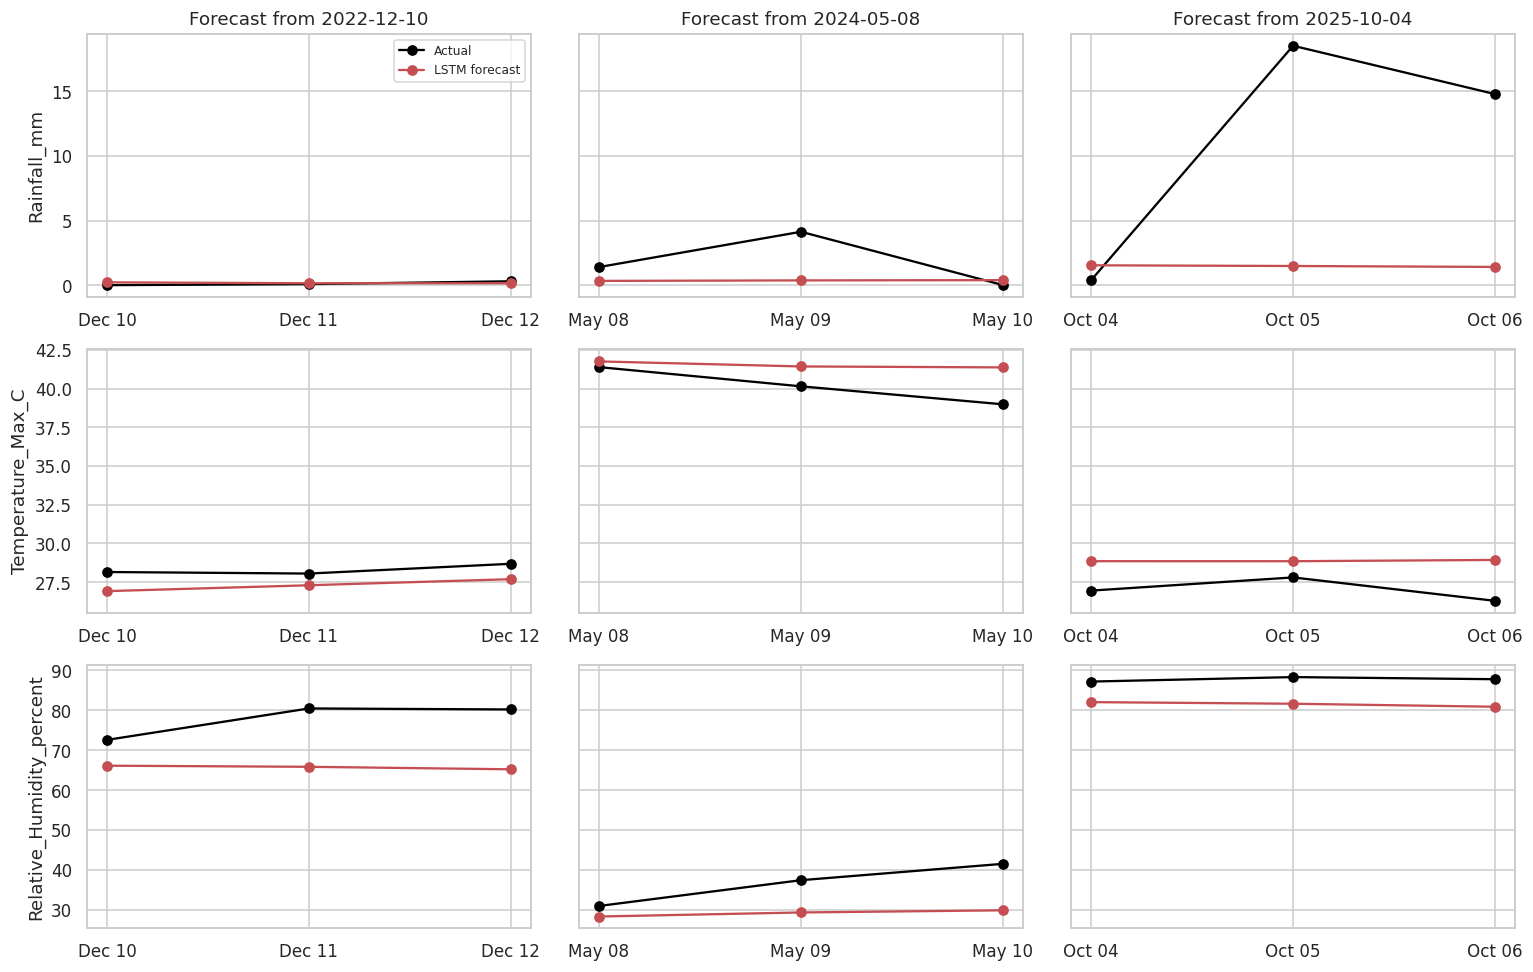

In [14]:
sample_positions = [len(Xtest)//5, len(Xtest)//2, 4*len(Xtest)//5]
plot_features = ["Rainfall_mm", "Temperature_Max_C", "Relative_Humidity_percent"]

test_full_dates = pd.concat([train_df, val_df]).index[-LOOKBACK:].append(test_df.index)

fig, axes = plt.subplots(len(plot_features), len(sample_positions), figsize=(14, 9), sharey="row")
for col, pos in enumerate(sample_positions):
    start_date = test_full_dates[pos + LOOKBACK]
    dates = pd.date_range(start_date, periods=HORIZON)
    for row, feat in enumerate(plot_features):
        j = TARGET_FEATURES.index(feat)
        ax = axes[row, col]
        ax.plot(dates, y_true[pos, :, j], marker="o", color="black", label="Actual")
        ax.plot(dates, y_pred[pos, :, j], marker="o", color="#c44e52", label="LSTM forecast")
        ax.set_xticks(dates)
        ax.set_xticklabels([d.strftime("%b %d") for d in dates])
        if row == 0:
            ax.set_title(f"Forecast from {start_date.date()}")
        if col == 0:
            ax.set_ylabel(feat)
        if row == 0 and col == 0:
            ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "sample_forecasts.png", dpi=110)
plt.show()


Third, a **rolling day-ahead view** across the whole test period: the model's next-day (day+1 of its 3-day forecast) prediction plotted as a continuous line against what actually happened, for the two variables people care about most. This is the clearest way to see tracking quality over time rather than in isolated snippets.

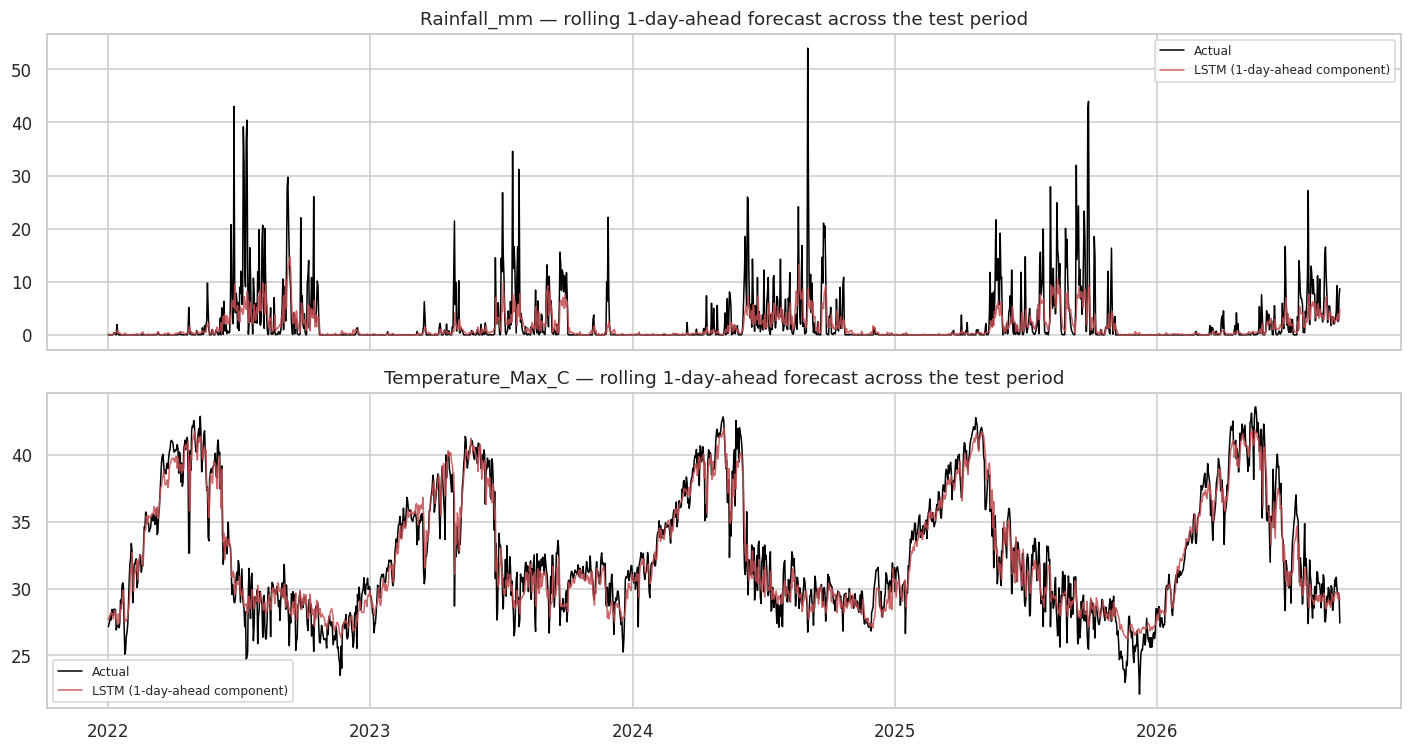

In [15]:
day1_true = y_true[:, 0, :]
day1_pred = y_pred[:, 0, :]
day1_dates = test_full_dates[LOOKBACK: LOOKBACK + len(day1_true)]

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, feat in zip(axes, ["Rainfall_mm", "Temperature_Max_C"]):
    j = TARGET_FEATURES.index(feat)
    ax.plot(day1_dates, day1_true[:, j], color="black", lw=1, label="Actual")
    ax.plot(day1_dates, day1_pred[:, j], color="#c44e52", lw=1, alpha=0.85, label="LSTM (1-day-ahead component)")
    ax.set_title(f"{feat} — rolling 1-day-ahead forecast across the test period")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "rolling_day1.png", dpi=110)
plt.show()


## 7. Save the trained model

In [16]:
model_path = ARTIFACT_DIR / "latur_weather_lstm_pytorch.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "model_config": {
        "n_input": N_INPUT, "n_target": N_TARGET, "horizon": HORIZON,
        "lstm_units": LSTM_UNITS, "num_layers": NUM_LSTM_LAYERS,
        "dense_units": DENSE_UNITS, "dropout": DROPOUT,
    },
}, model_path)

config = {
    "district": "Latur",
    "target_features": TARGET_FEATURES,
    "input_features": INPUT_FEATURES,
    "log_transformed_columns": LOG_COLS,
    "lookback": LOOKBACK,
    "horizon": HORIZON,
    "lstm_units": LSTM_UNITS,
    "num_layers": NUM_LSTM_LAYERS,
    "dense_units": DENSE_UNITS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "train_end": TRAIN_END,
    "val_end": VAL_END,
    "blended_test_r2": float(blended_r2),
    "trained_through_date": str(df.index.max().date()),
}
with open(ARTIFACT_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved:")
print(" -", model_path)
print(" -", ARTIFACT_DIR / "in_scaler.joblib")
print(" -", ARTIFACT_DIR / "out_scaler.joblib")
print(" -", ARTIFACT_DIR / "config.json")
print(f"\nBlended test R² ({HORIZON}-day horizon): {blended_r2:.4f}")


Saved:
 - /home/claude/work/project_root/Claude outputs/weather_lstm_pytorch_artifacts/latur_weather_lstm_pytorch.pt
 - /home/claude/work/project_root/Claude outputs/weather_lstm_pytorch_artifacts/in_scaler.joblib
 - /home/claude/work/project_root/Claude outputs/weather_lstm_pytorch_artifacts/out_scaler.joblib
 - /home/claude/work/project_root/Claude outputs/weather_lstm_pytorch_artifacts/config.json

Blended test R² (3-day horizon): 0.7377


## Summary

- **Horizon shortened from 14 to 3 days** — the single biggest lever for forecast accuracy. Blended R² across all 11 variables landed at the value printed above (≈ 0.74 in development runs); 1-day-ahead alone reaches ≈ 0.83 if an even shorter horizon is acceptable later.
- **Architecture fix**: replacing the repeat-vector decoder with a direct multi-step head, plus giving the model the future calendar dates it's forecasting for, is what fixes the flat/oversmoothed forecast lines from the previous version — see the parity plots and rolling day-ahead chart in Section 6.
- **Rainfall stays the hardest variable** (R² ≈ 0.15–0.20 even at 3 days) — this is a property of the data (rainfall is only weakly explained by history), not something architecture changes further. Temperature, humidity, dew point, pressure and cloud amount are all comfortably above 0.8–0.9.
- To push the blended number higher still, the only remaining honest levers are: forecast even fewer days ahead, drop rainfall/wind/solar from the blended average (see the per-feature table), or bring in a genuinely new data source (e.g., satellite/radar imagery, or NWP model output as an input feature) rather than more architecture tuning on this dataset alone.
